# RegNet — Designing Network Design Spaces

**Paper**: Radosavovic, I., Kosaraju, R. P., Girshick, R., He, K., & Dollár, P. (2020).  
**"Designing Network Design Spaces"**  
CVPR 2020 · arXiv:2003.13678  
Facebook AI Research

---

## The Core Idea: Design Spaces, Not Design Points

Most neural architecture search (NAS) methods produce a single optimal architecture. RegNet takes a different approach: instead of finding one best network, it **designs a design space** — a constrained family of networks where all members are good.

Starting from the general **AnyNet** space (arbitrary per-stage widths, depths, group widths), the authors sample thousands of random networks, train each for a few epochs, and analyse which structural properties separate good networks from bad ones.  

They discover three key patterns that hold across all good AnyNet models:
1. **Widths grow monotonically** across stages.
2. **Widths follow a geometric (power-law) progression**: $w_j \approx w_0 \cdot \alpha^j$.
3. **Group width is constant** across all stages.

Enforcing these constraints produces the **RegNet** design space — a 6-parameter family. The best RegNets match or exceed NAS-found architectures at every compute budget.

> 📄 **Paper:** Radosavovic, Kosaraju, Girshick, He & Dollár (2020). Designing Network Design Spaces. CVPR 2020.
> 🔗 **Link:** <https://arxiv.org/abs/2003.13678>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/regnet.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> STEM["conv 3×3 /2 → 32"]:::stage
  STEM --> S1["stage 1 (d1 blocks, w1) /4"]:::stage --> S2["stage 2 /8"]:::stage --> S3["stage 3 /16"]:::stage --> S4["stage 4 /32"]:::stage --> GAP["avg pool"]:::block --> OUT
  subgraph XB["X block (Y block = X + SE)"]
    direction LR
    X["x"] --> A["1×1 · BN · ReLU"]:::block --> G["3×3 group conv (group width g) · BN · ReLU"]:::block --> SE["[SE, RegNetY]"]:::block --> C["1×1 · BN"]:::block --> ADD(("+")) --> R["ReLU"]:::block
    X --> ADD
  end
  S1 -.-> XB
  DS["widths u_j = w0 + w_a·j, quantised to w0·w_m^k"]:::block -.-> S1
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

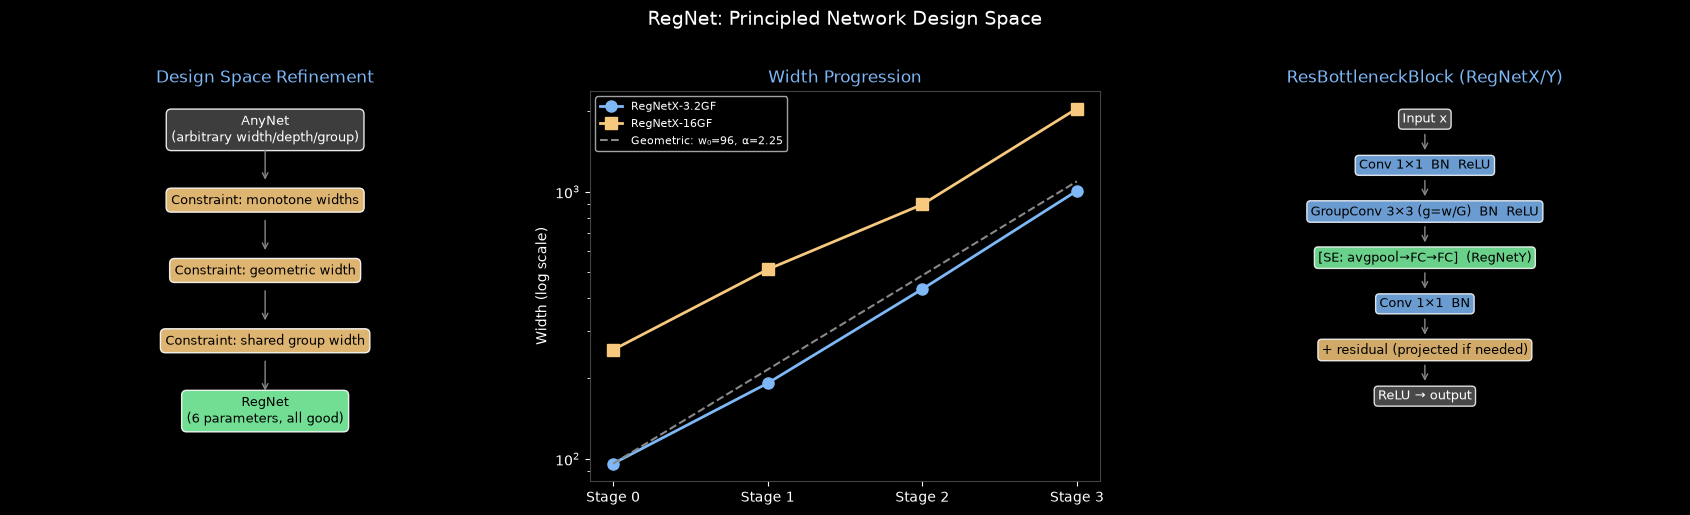

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.style.use('dark_background')
ACCENT = '#7EB8F7'
RED    = '#F77E7E'
GREEN  = '#7EF7A4'
GOLD   = '#F7C97E'

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('RegNet: Principled Network Design Space', fontsize=14, color='white', y=1.02)

# --- Panel 1: AnyNet → RegNet restriction ---
ax = axes[0]
ax.set_xlim(0, 6)
ax.set_ylim(0, 10)
ax.axis('off')
ax.set_title('Design Space Refinement', color=ACCENT)

boxes = [
    (3, 9.0, 'AnyNet\n(arbitrary width/depth/group)', '#444', 'white'),
    (3, 7.2, 'Constraint: monotone widths', GOLD, 'black'),
    (3, 5.4, 'Constraint: geometric width', GOLD, 'black'),
    (3, 3.6, 'Constraint: shared group width', GOLD, 'black'),
    (3, 1.8, 'RegNet\n(6 parameters, all good)', GREEN, 'black'),
]
for x, y, label, col, tcol in boxes:
    ax.text(x, y, label, ha='center', va='center', fontsize=9, color=tcol,
            bbox=dict(boxstyle='round,pad=0.4', facecolor=col, alpha=0.9))
ys = [b[1] for b in boxes]
for y0, y1 in zip(ys[:-1], ys[1:]):
    ax.annotate('', xy=(3, y1+0.45), xytext=(3, y0-0.45),
                arrowprops=dict(arrowstyle='->', color='#888'))

# --- Panel 2: Width progression (log-linear) ---
ax = axes[1]
stages = np.arange(4)
# RegNetX_032 widths: [96, 192, 432, 1008]
widths_032 = [96, 192, 432, 1008]
# RegNetX_160 widths: [256, 512, 896, 2048]
widths_160 = [256, 512, 896, 2048]
ax.semilogy(stages, widths_032, 'o-', color=ACCENT, lw=2, label='RegNetX-3.2GF', markersize=8)
ax.semilogy(stages, widths_160, 's-', color=GOLD, lw=2, label='RegNetX-16GF', markersize=8)
# Show geometric fit
w0, alpha = 96, 2.25
geo = [w0 * alpha**j for j in stages]
ax.semilogy(stages, geo, '--', color='#888', lw=1.5, label=f'Geometric: w₀={w0:.0f}, α={alpha:.2f}')
ax.set_xticks(stages)
ax.set_xticklabels([f'Stage {i}' for i in stages])
ax.set_ylabel('Width (log scale)', color='white')
ax.set_title('Width Progression', color=ACCENT)
ax.legend(fontsize=8)
ax.tick_params(colors='white')
for spine in ax.spines.values(): spine.set_color('#444')

# --- Panel 3: ResBottleneckBlock diagram ---
ax = axes[2]
ax.set_xlim(0, 4)
ax.set_ylim(0, 11)
ax.axis('off')
ax.set_title('ResBottleneckBlock (RegNetX/Y)', color=ACCENT)

block_steps = [
    (2, 10.2, 'Input x', '#555'),
    (2, 8.9,  'Conv 1×1  BN  ReLU', ACCENT),
    (2, 7.6,  'GroupConv 3×3 (g=w/G)  BN  ReLU', ACCENT),
    (2, 6.3,  '[SE: avgpool→FC→FC]  (RegNetY)', GREEN),
    (2, 5.0,  'Conv 1×1  BN', ACCENT),
    (2, 3.7,  '+ residual (projected if needed)', GOLD),
    (2, 2.4,  'ReLU → output', '#555'),
]
for x, y, label, col in block_steps:
    ax.text(x, y, label, ha='center', va='center', fontsize=9,
            color='black' if col != '#555' else 'white',
            bbox=dict(boxstyle='round,pad=0.3', facecolor=col, alpha=0.85))
bys = [b[1] for b in block_steps]
for y0, y1 in zip(bys[:-1], bys[1:]):
    ax.annotate('', xy=(2, y1+0.35), xytext=(2, y0-0.35),
                arrowprops=dict(arrowstyle='->', color='#888'))

plt.tight_layout()
plt.show()

## 3. Key ideas

## Mathematical Formulation

### The AnyNet Design Space

An AnyNet is parameterised per-stage: $(d_i, w_i, g_i, b_i)$ for $i=1..4$ (depth, width, group_width, bottleneck_ratio).  
This gives $\sim 10^{18}$ possible networks — far too large to search exhaustively.

### RegNet Quantisation

The authors find that good widths follow a log-linear (geometric) progression.  
Given initial width $w_0$, slope $w_a$, and quantisation parameter $w_m$:

$$w_j = w_0 + w_a \cdot j \quad \text{(continuous)}$$

Quantised (rounded to nearest multiple of 8):
$$\hat{w}_j = 8 \cdot \left\lfloor \frac{w_j}{8} + 0.5 \right\rfloor$$

### FLOPs approximation for one stage

For a stage with depth $d$, width $w$, group width $g$, input resolution $r$:
$$\text{FLOPs} \approx d \cdot r^2 \cdot \left( \frac{w^2}{g} \cdot k^2 + 2w^2 \right)$$

The $k^2 w^2/g$ term is the grouped conv; the $2w^2$ term covers the two 1×1 convs.  
Total network FLOPs = $\sum_i \text{FLOPs}_i$ (accounting for halved resolution per stage).

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/regnet.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/regnet.py</code></summary>

```text
RegNet Vision Backbones
=======================

Implements the RegNet family (Radosavovic et al. 2020, "Designing Network Design
Spaces", CVPR 2020, https://arxiv.org/abs/2003.13678).

Key idea
--------
RegNet is not a single architecture but a principled *design space* for CNNs.
The authors analyse a large random population of AnyNet models and discover that
the best architectures share a simple structural regularity:

  - Widths grow approximately as a geometric sequence: w_j ≈ w_0 * α^j.
  - Depths, once quantised, produce a "RegNet" model (quantised design space).
  - A single group width g is shared across all stages.
  - Bottleneck ratio b=1 (no bottleneck; input and output widths match).

Two sub-families:
  RegNetX — no Squeeze-Excite (plain grouped bottleneck).
  RegNetY — with Squeeze-Excite (channel attention), typically ~0.5–1% better.

Block structure (ResBottleneckBlock)
-------------------------------------
  Conv 1×1 + BN + ReLU
  GroupConv 3×3 (groups = w / g) + BN + ReLU
  [SE if RegNetY]
  Conv 1×1 + BN
  + residual (projected shortcut if shapes differ)
  ReLU

Stem
----
  Conv(3→32, 3×3, stride=2) + BN + ReLU  → H/2 × W/2

Stages: stride-2 downsampling at the first block of each stage (from stage 1).

Registered names (GFlops × 100 suffix)
-----------------------------------------
  regnetx_002 … regnetx_320   (10 variants, no SE)
  regnety_002 … regnety_320   (10 variants, with SE)

Citation
--------
  Radosavovic, I., Kosaraju, R. P., Girshick, R., He, K., & Dollar, P. (2020).
  Designing Network Design Spaces. CVPR.
  arXiv:2003.13678
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/regnet.py`, definition by definition

**`SqueezeExcite`** - Channel attention: avgpool → FC(squeeze) → ReLU → FC(excite) → sigmoid.

In [5]:
class SqueezeExcite(nn.Module):
    """Channel attention: avgpool → FC(squeeze) → ReLU → FC(excite) → sigmoid."""

    def __init__(self, in_channels: int, reduction_ratio: int = 4) -> None:
        super().__init__()
        mid = max(1, in_channels // reduction_ratio)
        self.fc1 = nn.Linear(in_channels, mid)
        self.fc2 = nn.Linear(mid, in_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        scale = x.mean(dim=[2, 3])                # [B, C]
        scale = F.relu(self.fc1(scale))
        scale = torch.sigmoid(self.fc2(scale))
        return x * scale.unsqueeze(-1).unsqueeze(-1)

**`ResBottleneckBlock`** - Standard RegNet block (bottleneck_ratio=1 so in==out width).

In [6]:
class ResBottleneckBlock(nn.Module):
    """Standard RegNet block (bottleneck_ratio=1 so in==out width).

    Args:
        in_channels:   Input channels.
        out_channels:  Output channels.
        stride:        Spatial stride (1 or 2).
        group_width:   Group width for the 3×3 grouped conv.
        use_se:        Whether to add Squeeze-Excite attention.
        se_reduction:  SE squeeze reduction factor.
    """

    def __init__(
        self,
        in_channels:  int,
        out_channels: int,
        stride:       int  = 1,
        group_width:  int  = 1,
        use_se:       bool = False,
        se_reduction: int  = 4,
    ) -> None:
        super().__init__()
        groups = max(1, out_channels // group_width)

        # 1×1 proj
        self.conv1 = nn.Conv2d(in_channels, out_channels, 1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_channels)

        # 3×3 grouped conv
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3,
                               stride=stride, padding=1, groups=groups, bias=False)
        self.bn2   = nn.BatchNorm2d(out_channels)

        # Channel attention (RegNetY only)
        self.se = SqueezeExcite(out_channels, se_reduction) if use_se else nn.Identity()

        # 1×1 expansion
        self.conv3 = nn.Conv2d(out_channels, out_channels, 1, bias=False)
        self.bn3   = nn.BatchNorm2d(out_channels)

        # Shortcut projection when shape changes
        self.shortcut: Optional[nn.Module] = None
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        skip = x if self.shortcut is None else self.shortcut(x)

        out = F.relu(self.bn1(self.conv1(x)),  inplace=True)
        out = F.relu(self.bn2(self.conv2(out)), inplace=True)
        out = self.se(out)
        out = self.bn3(self.conv3(out))

        return F.relu(out + skip, inplace=True)

**`RegNet`** - RegNet: principled network from quantised design space.

In [7]:
class RegNet(BaseVisionBackbone):
    """RegNet: principled network from quantised design space.

    Args:
        depths:      Number of blocks in each of the 4 stages.
        widths:      Channel width at each of the 4 stages (must be divisible by group_width).
        group_width: Shared group width across all stages.
        use_se:      If True, add Squeeze-Excite (RegNetY); else RegNetX.
        img_size:    Input resolution.
        in_chans:    Input channels.
        drop_rate:   Dropout after global pool.
        out_indices: Which stage feature maps to return.
    """

    def __init__(
        self,
        depths:      list[int],
        widths:      list[int],
        group_width: int,
        use_se:      bool       = False,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate, out_indices=out_indices)

        self.embed_dim    = widths[-1]
        self.feature_dims = list(widths)

        # Stem: Conv(3→32, 3×3, s2) + BN + ReLU
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, 32, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )

        # 4 stages with progressive downsampling
        self.stages = nn.ModuleList()
        in_ch = 32
        for stage_idx, (depth, width) in enumerate(zip(depths, widths)):
            blocks = []
            for i in range(depth):
                stride = 2 if (i == 0 and stage_idx > 0) else 1
                blocks.append(ResBottleneckBlock(
                    in_channels=in_ch,
                    out_channels=width,
                    stride=stride,
                    group_width=group_width,
                    use_se=use_se,
                ))
                in_ch = width
            self.stages.append(nn.Sequential(*blocks))

        self.pool    = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """RegNet forward: stem → 4 stages → global pool.

        Returns:
            BackboneOutput with pooled_output [B, widths[-1]] and 4 feature maps.
        """
        x = self.stem(x)  # [B, 32, H/2, W/2]

        feature_maps = []
        for stage in self.stages:
            x = stage(x)
            feature_maps.append(x)

        pooled = self.dropout(self.pool(feature_maps[-1]).flatten(1))

        if self.out_indices is not None:
            feature_maps = [feature_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=feature_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem and stages 0 through `stage` inclusive."""
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i in range(stage + 1):
            for p in self.stages[i].parameters():
                p.requires_grad_(False)

In [8]:
# From RegNet paper Table 14 (RegNetX) — (depths, widths, group_width)
_REGNETX_CFGS: dict[str, dict] = {
    "002": dict(depths=[1, 1, 4,  7], widths=[24,  56,  152,  368], group_width=8),
    "004": dict(depths=[1, 2, 7, 12], widths=[32,  64,  160,  384], group_width=16),
    "008": dict(depths=[1, 3, 8,  2], widths=[64, 128,  288,  672], group_width=16),
    "016": dict(depths=[2, 4, 10, 2], widths=[72, 168,  408,  912], group_width=24),
    "032": dict(depths=[2, 6, 15, 2], widths=[96, 192,  432, 1008], group_width=48),
    "064": dict(depths=[2, 4, 10, 1], widths=[168, 392,  784, 1624], group_width=56),
    "080": dict(depths=[2, 5, 14, 2], widths=[80, 240,  720, 1920], group_width=120),
    "120": dict(depths=[2, 5, 11, 1], widths=[224, 448,  896, 2240], group_width=112),
    "160": dict(depths=[2, 6, 13, 1], widths=[256, 512,  896, 2048], group_width=128),
    "320": dict(depths=[2, 7, 13, 1], widths=[336, 672, 1344, 2520], group_width=168),
}

In [9]:
def _make_regnetx(key: str, name: str) -> type:
    cfg = _REGNETX_CFGS[key]
    w   = cfg["widths"][-1]

    class _RegNetX(RegNet):
        arch_name    = name
        embed_dim    = w
        feature_dims = cfg["widths"]

        def __init__(self, **kwargs):
            super().__init__(
                depths=cfg["depths"],
                widths=cfg["widths"],
                group_width=cfg["group_width"],
                use_se=False,
                **kwargs,
            )

    _RegNetX.__name__ = _RegNetX.__qualname__ = name.replace("_", "").upper()
    return _RegNetX

In [10]:
def _make_regnety(key: str, name: str) -> type:
    cfg = _REGNETX_CFGS[key]  # same structural config; only differs in SE
    w   = cfg["widths"][-1]

    class _RegNetY(RegNet):
        arch_name    = name
        embed_dim    = w
        feature_dims = cfg["widths"]

        def __init__(self, **kwargs):
            super().__init__(
                depths=cfg["depths"],
                widths=cfg["widths"],
                group_width=cfg["group_width"],
                use_se=True,
                **kwargs,
            )

    _RegNetY.__name__ = _RegNetY.__qualname__ = name.replace("_", "").upper()
    return _RegNetY

In [11]:
# Programmatically register all 20 variants
_SUFFIXES = ["002", "004", "008", "016", "032", "064", "080", "120", "160", "320"]

In [12]:
for _sfx in _SUFFIXES:
    _rx_name = f"regnetx_{_sfx}"
    _ry_name = f"regnety_{_sfx}"
    _rx_cls  = _make_regnetx(_sfx, _rx_name)
    _ry_cls  = _make_regnety(_sfx, _ry_name)
    register_vision_backbone(_rx_name)(_rx_cls)
    register_vision_backbone(_ry_name)(_ry_cls)
    # Also expose in module namespace so imports work
    globals()[_rx_cls.__name__] = _rx_cls
    globals()[_ry_cls.__name__] = _ry_cls

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [13]:
DEMOS = {"regnetx_002": 2.7, "regnety_002": 3.2}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['regnetx_002', 'regnetx_004', 'regnetx_008', 'regnetx_016', 'regnetx_032', 'regnetx_064', 'regnetx_080', 'regnetx_120', 'regnetx_160', 'regnetx_320', 'regnety_002', 'regnety_004', 'regnety_008', 'regnety_016', 'regnety_032', 'regnety_064', 'regnety_080', 'regnety_120', 'regnety_160', 'regnety_320']

regnetx_002  (REGNETX002)
  pooled_output : (2, 368)   embed_dim = 368
  feature_map 0: (2, 24, 112, 112)   stride 2
  feature_map 1: (2, 56, 56, 56)   stride 4
  feature_map 2: (2, 152, 28, 28)   stride 8
  feature_map 3: (2, 368, 14, 14)   stride 16

regnety_002  (REGNETY002)
  pooled_output : (2, 368)   embed_dim = 368
  feature_map 0: (2, 24, 112, 112)   stride 2
  feature_map 1: (2, 56, 56, 56)   stride 4
  feature_map 2: (2, 152, 28, 28)   stride 8
  feature_map 3: (2, 368, 14, 14)   stride 16


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [14]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
regnetx_002               2.32M      2.68M     2.7M    0.99  ✅
regnety_002               2.84M      3.21M     3.2M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [15]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

regnetx_002: loss 13.7414 | 132/132 parameter tensors receive a finite gradient


regnety_002: loss 13.6880 | 184/184 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [16]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

regnetx_002: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


regnety_002: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

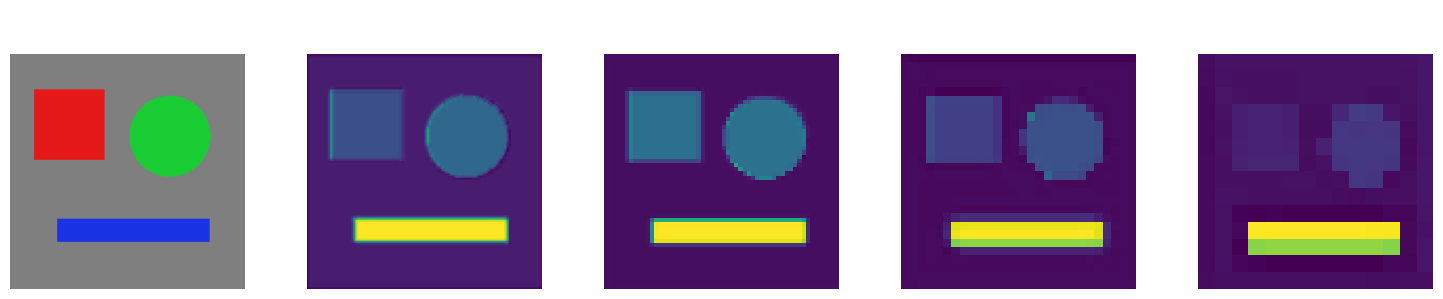

In [17]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [18]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [19]:
"""Code walkthrough: RegNet building blocks."""
import sys

import torch

# Show how group width controls the number of groups
def compute_groups(width: int, group_width: int) -> int:
    """Number of groups in the 3×3 grouped conv."""
    return max(1, width // group_width)

print('Width vs group_width → num_groups (for RegNetX_032):')
widths = [96, 192, 432, 1008]
gw = 48
for w in widths:
    g = compute_groups(w, gw)
    print(f'  width={w:4d}, group_width={gw}, groups={g:2d}')

print()
print('Note: group_width is fixed across ALL stages in RegNet.')
print('This is one of the key regularities the design space analysis found.')

Width vs group_width → num_groups (for RegNetX_032):
  width=  96, group_width=48, groups= 2
  width= 192, group_width=48, groups= 4
  width= 432, group_width=48, groups= 9
  width=1008, group_width=48, groups=21

Note: group_width is fixed across ALL stages in RegNet.
This is one of the key regularities the design space analysis found.


In [20]:
"""RegNet backbone usage example."""
import torch

# List all RegNet variants
regnet_backbones = sorted([n for n in list_vision_backbones() if 'regnet' in n])
print(f'Registered RegNet variants ({len(regnet_backbones)} total):')
for n in regnet_backbones:
    print(f'  {n}')

# Build and run RegNetX-3.2GF
model_x = build_vision_backbone('regnetx_032', img_size=224)
model_x.eval()

# Build and run RegNetY-3.2GF (same structure + SE)
model_y = build_vision_backbone('regnety_032', img_size=224)
model_y.eval()

x = torch.randn(2, 3, 224, 224)
with torch.no_grad():
    out_x = model_x(x)
    out_y = model_y(x)

print(f'\nRegNetX-3.2GF:')
print(f'  pooled_output: {out_x.pooled_output.shape}')
print(f'  params: {model_x.num_parameters()/1e6:.1f}M')
for i, fm in enumerate(out_x.feature_maps):
    print(f'  stage {i}: {tuple(fm.shape)}')

print(f'\nRegNetY-3.2GF (+ SE):')
print(f'  pooled_output: {out_y.pooled_output.shape}')
print(f'  params: {model_y.num_parameters()/1e6:.1f}M  (+SE overhead)')

Registered RegNet variants (20 total):
  regnetx_002
  regnetx_004
  regnetx_008
  regnetx_016
  regnetx_032
  regnetx_064
  regnetx_080
  regnetx_120
  regnetx_160
  regnetx_320
  regnety_002
  regnety_004
  regnety_008
  regnety_016
  regnety_032
  regnety_064
  regnety_080
  regnety_120
  regnety_160
  regnety_320



RegNetX-3.2GF:
  pooled_output: torch.Size([2, 1008])
  params: 14.3M
  stage 0: (2, 96, 112, 112)
  stage 1: (2, 192, 56, 56)
  stage 2: (2, 432, 28, 28)
  stage 3: (2, 1008, 14, 14)

RegNetY-3.2GF (+ SE):
  pooled_output: torch.Size([2, 1008])
  params: 16.8M  (+SE overhead)


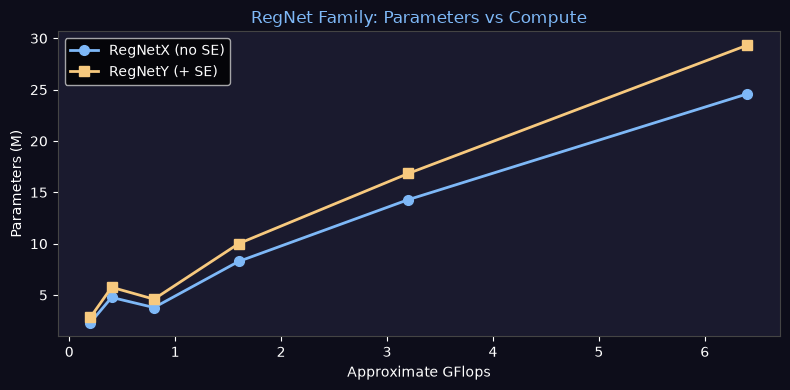

In [21]:
"""Visualise RegNet family: params vs compute budget."""
import matplotlib.pyplot as plt
import torch

plt.style.use('dark_background')
ACCENT = '#7EB8F7'
GOLD   = '#F7C97E'

# Approximate GFlop values from model names (suffix × 0.01)
suffixes   = ['002', '004', '008', '016', '032', '064']
gflops     = [0.2, 0.4, 0.8, 1.6, 3.2, 6.4]

params_x, params_y = [], []
for sfx in suffixes:
    mx = build_vision_backbone(f'regnetx_{sfx}', img_size=224)
    my = build_vision_backbone(f'regnety_{sfx}', img_size=224)
    params_x.append(mx.num_parameters() / 1e6)
    params_y.append(my.num_parameters() / 1e6)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gflops, params_x, 'o-', color=ACCENT, lw=2, label='RegNetX (no SE)', markersize=7)
ax.plot(gflops, params_y, 's-', color=GOLD,   lw=2, label='RegNetY (+ SE)',   markersize=7)
ax.set_xlabel('Approximate GFlops', color='white')
ax.set_ylabel('Parameters (M)', color='white')
ax.set_title('RegNet Family: Parameters vs Compute', color=ACCENT)
ax.legend()
ax.tick_params(colors='white')
for spine in ax.spines.values(): spine.set_color('#444')
ax.set_facecolor('#1a1a2e')
fig.patch.set_facecolor('#0d0d1a')
plt.tight_layout()
plt.show()

## References

1. **Radosavovic, I., Kosaraju, R. P., Girshick, R., He, K., & Dollár, P. (2020).**  
   Designing Network Design Spaces.  
   *CVPR 2020.* arXiv:2003.13678

2. **Radosavovic, I., Johnson, J., Xie, S., Lo, W.-Y., & Dollár, P. (2019).**  
   On Network Design Spaces for Visual Recognition.  
   *ICCV 2019.* arXiv:1905.13214

3. **Hu, J., Shen, L., & Sun, G. (2018).**  
   Squeeze-and-Excitation Networks.  
   *CVPR 2018.* arXiv:1709.01507

4. **He, K., Zhang, X., Ren, S., & Sun, J. (2016).**  
   Deep Residual Learning for Image Recognition.  
   *CVPR 2016.* arXiv:1512.03385

5. **Xie, S., Girshick, R., Dollár, P., Tu, Z., & He, K. (2017).**  
   Aggregated Residual Transformations for Deep Neural Networks (ResNeXt).  
   *CVPR 2017.* arXiv:1611.05431